# Water bridges comparative analysis

In [335]:
import pandas as pd
from scipy.stats import mannwhitneyu
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Note: check the timeseries plots computed through snakemake to compare the average number of contacts below the threshold per timeframe and over the analyzed period. This notebook focuses on the analysis of the pair contacts.

## Load data

In [336]:
wt_dfs = []
for rep in range(1, 4):
    wb_df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/002.hbonds/waterbridges.csv')
    wt_dfs.append(wb_df)

T419R_dfs = []
for rep in range(1, 4):
    wb_df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/002.hbonds/waterbridges.csv')
    T419R_dfs.append(wb_df)

In [337]:
len(wt_dfs)

3

In [338]:
len(T419R_dfs)

3

In [339]:
for df in wt_dfs:
    print(df.shape)

(1459, 11)
(518, 11)
(2557, 11)


In [340]:
for df in T419R_dfs:
    print(df.shape)

(2349, 11)
(1306, 11)
(743, 11)


The number of identified water bridges (rows) varies greatly within replicates.

In [341]:
wt_dfs[1].head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle
0,100900.0,14154,417321,ARG,283,HH21,WAT,99835,H2,2.407864,120.306876
1,100900.0,417321,19732,WAT,99835,H2,DA,6,H2,2.974124,139.508148
2,101200.0,14155,152887,ARG,283,HH22,WAT,33727,O,3.146806,148.007760
3,101200.0,152889,19732,WAT,33727,H2,DA,6,H2,3.218076,123.058982
4,102000.0,14148,347531,ARG,283,HE,WAT,82388,O,2.109737,149.223424


Add adjusted residue numbers.

In [342]:
for df in (wt_dfs + T419R_dfs):
    df["sele1_resid_adj"] = np.where(
        (df["sele1_resnm"].str.match(r'^[A-Za-z]{3}$')) & (df["sele1_resnm"] != "WAT"),
        df["sele1_resid"] + 135,
        df["sele1_resid"]
    )
    df["sele2_resid_adj"] = np.where(
        (df["sele2_resnm"].str.match(r'^[A-Za-z]{3}$')) & (df["sele2_resnm"] != "WAT"),
        df["sele2_resid"] + 135,
        df["sele2_resid"]
    )

In [343]:
wt_dfs[1].head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle,sele1_resid_adj,sele2_resid_adj
0,100900.0,14154,417321,ARG,283,HH21,WAT,99835,H2,2.407864,120.306876,418,99835
1,100900.0,417321,19732,WAT,99835,H2,DA,6,H2,2.974124,139.508148,99835,6
2,101200.0,14155,152887,ARG,283,HH22,WAT,33727,O,3.146806,148.007760,418,33727
3,101200.0,152889,19732,WAT,33727,H2,DA,6,H2,3.218076,123.058982,33727,6
4,102000.0,14148,347531,ARG,283,HE,WAT,82388,O,2.109737,149.223424,418,82388


## Filter direct hydrogen bonds and aggregate data

The identified "water bridges" include bonds that are in fact direct hydrogen bonds between the protein and DNA. We will filter these out to focus on water bridges.

In [344]:
# Aggregate hbond counts for each unique hbond across replicates or methods
def aggregate_hbonds(df_list, label):
    combined = pd.concat(df_list)
    combined= combined[(combined["sele1_resnm"] == "WAT") | (combined["sele2_resnm"] == "WAT")]
    agg_df = combined.groupby(['sele1_index', 'sele2_index', 'sele1_resid_adj', 
                               'sele2_resid_adj', 'sele1_resnm', 'sele2_resnm']).size().reset_index(name='count')

    agg_df['group'] = label
    return combined, agg_df

In [345]:

wt_combined, wt_agg = aggregate_hbonds(wt_dfs, 'wt')
mut_combined, mut_agg = aggregate_hbonds(T419R_dfs, 'T419R')

In [346]:
wt_agg.sort_values("count", ascending=False).head()

,sele1_index,sele2_index,sele1_resid_adj,sele2_resid_adj,sele1_resnm,sele2_resnm,count,group
185,4784,159880,421,35475,GLU,WAT,48,wt
353,14151,272345,418,63591,ARG,WAT,48,wt
352,14151,272343,418,63591,ARG,WAT,48,wt
261,4785,212660,421,48670,GLU,WAT,47,wt
110,4774,66375,421,12099,GLU,WAT,45,wt


In [347]:
wt_agg[wt_agg["sele1_resnm"] != "WAT"]["sele1_resid_adj"].unique()

array([411, 413, 420, 421, 417, 418])

## Water bridges per frame

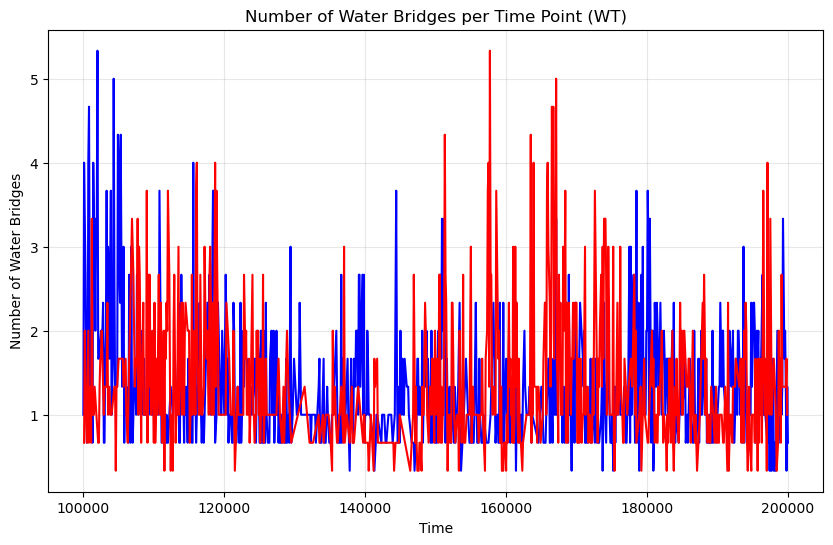

In [348]:
# Count rows per unique time value. Normalize for replicate number
time_counts_wt = wt_combined['time'].value_counts().sort_index() / len(wt_dfs)
time_counts_mut = mut_combined['time'].value_counts().sort_index() / len(T419R_dfs)

plt.figure(figsize=(10, 6))
plt.plot(time_counts_wt.index, time_counts_wt.values, color='blue')
plt.plot(time_counts_mut.index, time_counts_mut.values, color='red')
plt.xlabel('Time')
plt.ylabel('Number of Water Bridges')
plt.title('Number of Water Bridges per Time Point (WT)')
plt.grid(True, alpha=0.3)
plt.show()

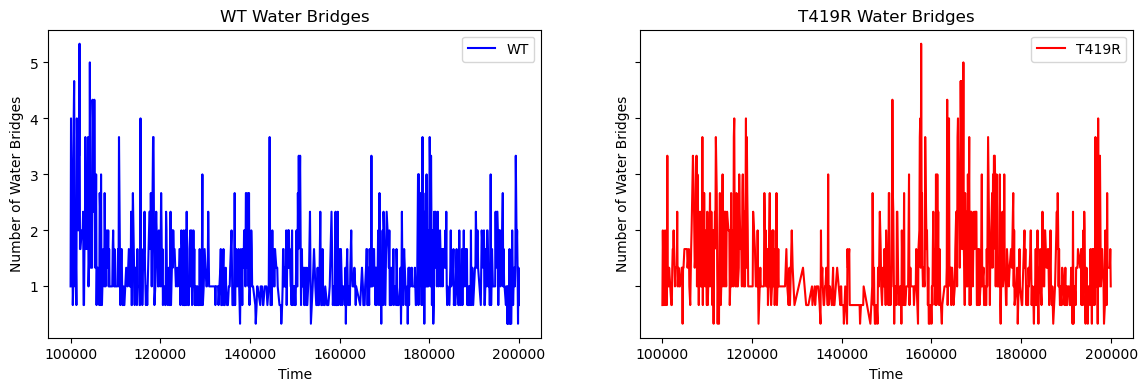

In [349]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
ax1, ax2 = axes.flatten()

ax1.plot(time_counts_wt.index, time_counts_wt.values, color='blue', label='WT')
ax2.plot(time_counts_mut.index, time_counts_mut.values, color='red', label='T419R')
ax1.set_xlabel('Time')
ax2.set_xlabel('Time')
ax1.set_ylabel('Number of Water Bridges')
ax2.set_ylabel('Number of Water Bridges')
ax1.set_title('WT Water Bridges')
ax2.set_title('T419R Water Bridges')
ax1.legend()
ax2.legend()

plt.show()

## Water bridges per residue

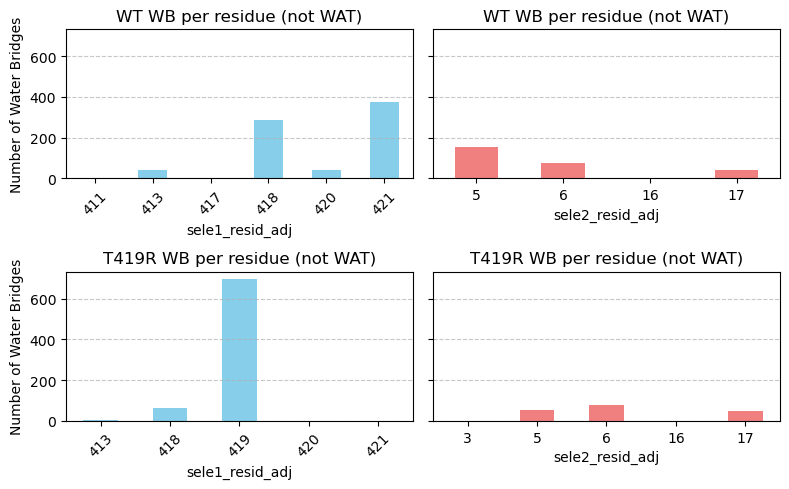

In [350]:
##### WT #####

sele1_filtered = wt_combined[wt_combined["sele1_resnm"] != "WAT"]
sele2_filtered = wt_combined[wt_combined["sele2_resnm"] != "WAT"]

# Count entries per resid
sele1_counts = sele1_filtered["sele1_resid_adj"].value_counts().sort_index() / len(wt_dfs)
sele2_counts = sele2_filtered["sele2_resid_adj"].value_counts().sort_index() / len(wt_dfs)

# Create side-by-side subplots
fig, axes = plt.subplots(2, 2, figsize=(8, 5), sharey=True)
ax1, ax2, ax3, ax4 = axes.flatten()

# Plot sele1_resid
sele1_counts.plot(kind="bar", color="skyblue", ax=ax1)
ax1.set_xlabel("sele1_resid_adj")
ax1.set_ylabel("Number of Water Bridges")
ax1.set_title("WT WB per residue (not WAT)")
ax1.grid(axis="y", linestyle="--", alpha=0.7)
ax1.tick_params(axis="x", rotation=45)

# Plot sele2_resid_adj
sele2_counts.plot(kind="bar", color="lightcoral", ax=ax2)
ax2.set_xlabel("sele2_resid_adj")
ax2.set_title("WT WB per residue (not WAT)")
ax2.grid(axis="y", linestyle="--", alpha=0.7)
ax2.tick_params(axis="x", rotation=0)

##### T419R #####

sele1_filtered = mut_combined[mut_combined["sele1_resnm"] != "WAT"]
sele2_filtered = mut_combined[mut_combined["sele2_resnm"] != "WAT"]

# Count entries per resid
sele1_counts = sele1_filtered["sele1_resid_adj"].value_counts().sort_index() / len(T419R_dfs)
sele2_counts = sele2_filtered["sele2_resid_adj"].value_counts().sort_index() / len(T419R_dfs)

# Plot sele1_resid_adj
sele1_counts.plot(kind="bar", color="skyblue", ax=ax3)
ax3.set_xlabel("sele1_resid_adj")
ax3.set_ylabel("Number of Water Bridges")
ax3.set_title("T419R WB per residue (not WAT)")
ax3.grid(axis="y", linestyle="--", alpha=0.7)
ax3.tick_params(axis="x", rotation=45)

# Plot sele2_resid_adj
sele2_counts.plot(kind="bar", color="lightcoral", ax=ax4)
ax4.set_xlabel("sele2_resid_adj")
ax4.set_title("T419R WB per residue (not WAT)")
ax4.grid(axis="y", linestyle="--", alpha=0.7)
ax4.tick_params(axis="x", rotation=0)

# Adjust layout
plt.tight_layout()
plt.show()

### Mapping protein-water-DNA triplets
#### WT

In [351]:
wt_combined["water_resid"] = np.where(wt_combined["sele1_resnm"] == "WAT", wt_combined["sele1_resid_adj"], wt_combined["sele2_resid_adj"])
wt_combined["water_sele"] = np.where(wt_combined["sele1_resnm"] == "WAT", 1, 2)

In [352]:
wt_combined.head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle,sele1_resid_adj,sele2_resid_adj,water_resid,water_sele
2,100100.0,14152,26681,ARG,283,HH12,WAT,2175,H2,2.252311,145.427315,418,2175,2175,2
3,100100.0,26681,19732,WAT,2175,H2,DA,6,H2,3.348624,140.971528,2175,6,2175,1
4,100100.0,14152,26679,ARG,283,HH12,WAT,2175,O,1.878968,157.572021,418,2175,2175,2
5,100100.0,14155,26681,ARG,283,HH22,WAT,2175,H2,2.634940,131.589160,418,2175,2175,2
6,100100.0,14155,26679,ARG,283,HH22,WAT,2175,O,3.060673,121.029822,418,2175,2175,2


Retrieve chains from PDB and add them to the dataframe. Note that the assigned chain value for WAT residues will be UNK (unknown).

In [353]:
# Map atom index to residue number, residue name and atom name
def get_atom_info(structure_file, atom_ids, chains=['A', 'B', 'C', 'D']):
    atom_info = {}
    with open(structure_file, 'r') as f:
        for line in f:
            # Check for ATOM or HETATM records
            if line.startswith(('ATOM', 'HETATM')):
                try:
                    atom_id = int(line[6:11].strip())      # Serial number (columns 7-11)
                    chain= line[21].strip()            # Chain ID (column 22)
                    
                    if atom_id in atom_ids and chain in chains:
                        atom_name = line[12:16].strip()    # Atom name (columns 13-16)
                        res_name = line[17:20].strip()     # Residue name (columns 18-20)
                        res_num = int(line[22:26].strip()) # Residue sequence number (columns 23-26)                        
                        # Store in dictionary
                        atom_info[atom_id] = {
                            'res_name': res_name,
                            'res_num': res_num,
                            'atom_name': atom_name,
                            'chain': chain
                        }
                except (ValueError, IndexError):
                    continue
    
    return atom_info

In [354]:
pdbfile = "../../data/1bf5/wt/rep0/gromacs/md_sys.pdb"
unique_atom_ids = set(wt_combined['sele1_index']).union(set(wt_combined['sele2_index']))

atom_info = get_atom_info(pdbfile, unique_atom_ids)

wt_combined['sele1_chain'] = wt_combined['sele1_index'].map(lambda x: atom_info.get(x, {}).get('chain', 'UNK'))
wt_combined['sele2_chain'] = wt_combined['sele2_index'].map(lambda x: atom_info.get(x, {}).get('chain', 'UNK'))

In [355]:
wt_combined.head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle,sele1_resid_adj,sele2_resid_adj,water_resid,water_sele,sele1_chain,sele2_chain
2,100100.0,14152,26681,ARG,283,HH12,WAT,2175,H2,2.252311,145.427315,418,2175,2175,2,B,UNK
3,100100.0,26681,19732,WAT,2175,H2,DA,6,H2,3.348624,140.971528,2175,6,2175,1,UNK,D
4,100100.0,14152,26679,ARG,283,HH12,WAT,2175,O,1.878968,157.572021,418,2175,2175,2,B,UNK
5,100100.0,14155,26681,ARG,283,HH22,WAT,2175,H2,2.634940,131.589160,418,2175,2175,2,B,UNK
6,100100.0,14155,26679,ARG,283,HH22,WAT,2175,O,3.060673,121.029822,418,2175,2175,2,B,UNK


In [356]:
def wb_triplets(combined_df):
    amino_acids = ["ARG", "LYS", "HIS", "SER", "THR", "ASN", "GLN", "ASP", "GLU", "ALA", "GLY", "PRO", "VAL", "LEU", "ILE", "MET", "PHE", "TYR", "TRP", "CYS"]
    bases = ["DA", "DT", "DG", "DC"]

    bridges = []
    for (time, water_resid), group in combined_df.groupby(["time", "water_resid"]):

        aa_to_water_rows = []
        water_to_base_rows = []
        
        # Loop over unique water_sele values in the group
        for water_sele in group["water_sele"].unique():
            sele_group = group[group["water_sele"] == water_sele]
            
            if water_sele == 1:
                aa_to_water = sele_group[(sele_group["sele2_resnm"].isin(amino_acids)) & (sele_group["sele1_resnm"] == "WAT")]
                water_to_base = sele_group[(sele_group["sele1_resnm"] == "WAT") & (sele_group["sele2_resnm"].isin(bases))]
            else: 
                aa_to_water = sele_group[(sele_group["sele1_resnm"].isin(amino_acids)) & (sele_group["sele2_resnm"] == "WAT")]
                water_to_base = sele_group[(sele_group["sele2_resnm"] == "WAT") & (sele_group["sele1_resnm"].isin(bases))]
            
            if not aa_to_water.empty:
                aa_to_water_rows.append(aa_to_water)
            if not water_to_base.empty:
                water_to_base_rows.append(water_to_base)
        
        # Combine rows into single DataFrames
        aa_to_water = pd.concat(aa_to_water_rows) if aa_to_water_rows else pd.DataFrame()
        water_to_base = pd.concat(water_to_base_rows) if water_to_base_rows else pd.DataFrame()

        if not aa_to_water.empty and not water_to_base.empty:
            for _, row1 in aa_to_water.iterrows():
                if water_sele == 1:
                    aa_resnm = row1["sele1_resnm"]
                    aa_resid = row1["sele1_resid_adj"]
                    aa_chain = row1["sele1_chain"]
                else:
                    aa_resnm = row1["sele2_resnm"]
                    aa_resid = row1["sele2_resid_adj"]
                    aa_chain = row1["sele2_chain"]
                for _, row2 in water_to_base.iterrows():
                    if water_sele == 1:
                        nt_resnm = row2["sele2_resnm"]
                        nt_resid = row2["sele2_resid_adj"]
                        nt_chain = row2["sele2_chain"]
                    else:
                        nt_resnm = row2["sele1_resnm"]
                        nt_resid = row2["sele1_resid_adj"]
                        nt_chain = row2["sele1_chain"]
                    bridges.append({
                        "time": time,
                        "aa": f"{aa_chain} {aa_resid} {aa_resnm}",
                        "nt": f"{nt_chain} {nt_resid} {nt_resnm}",
                        "water_resid": water_resid,
                        "distance1": row1["distance"],
                        "angle1": row1["angle"],
                        "distance2": row2["distance"],
                        "angle2": row2["angle"]
                    })
    return pd.DataFrame(bridges)

In [357]:
wt_triplets = wb_triplets(wt_combined)

In [358]:
wt_triplets.shape

(1518, 8)

In [359]:
wt_triplets.head(10)

,time,aa,nt,water_resid,distance1,angle1,distance2,angle2
0,100000.0,B 418 ARG,D 6 DA,60584,2.912734,161.218169,2.686466,127.536285
1,100000.0,B 418 ARG,D 6 DA,60584,2.163450,157.187995,2.686466,127.536285
2,100100.0,B 418 ARG,D 6 DA,2175,2.252311,145.427315,3.348624,140.971528
3,100100.0,B 418 ARG,D 6 DA,2175,1.878968,157.572021,3.348624,140.971528
4,100100.0,B 418 ARG,D 6 DA,2175,2.634940,131.589160,3.348624,140.971528
5,100100.0,B 418 ARG,D 6 DA,2175,3.060673,121.029822,3.348624,140.971528
6,100100.0,A 421 GLU,C 5 DA,29271,2.858864,137.455204,3.365205,130.716070
7,100100.0,A 421 GLU,C 5 DA,29271,2.595804,154.583784,3.365205,130.716070
8,100300.0,B 418 ARG,D 6 DA,3386,2.640113,150.540665,2.814983,142.289580
9,100300.0,B 418 ARG,D 6 DA,3386,2.066520,136.169322,2.814983,142.289580


Aggregate by residue pairs. The specific water molecule acting as a bridge is less relevant for the analysis.

In [360]:
wt_triplets_agg = wt_triplets.groupby(["aa", "nt"]).size().reset_index(name='count')

In [361]:
wt_triplets_agg.shape

(9, 3)

In [362]:
wt_triplets_agg.sort_values("count", ascending=False)

,aa,nt,count
4,A 421 GLU,C 5 DA,759
7,B 418 ARG,D 6 DA,448
2,A 413 LYS,D 17 DA,111
6,B 418 ARG,C 17 DA,109
3,A 420 ASN,C 5 DA,50
8,B 420 ASN,D 6 DA,27
5,B 417 THR,D 6 DA,6
0,A 411 GLU,D 17 DA,5
1,A 413 LYS,D 16 DA,3


1000 frames per replicate were analyzed.

In [363]:
wt_triplets_agg["occupancy"] = wt_triplets_agg["count"] / (len(wt_dfs) * 1000)

In [364]:
wt_triplets_agg.sort_values("count", ascending=False)

,aa,nt,count,occupancy
4,A 421 GLU,C 5 DA,759,0.253000
7,B 418 ARG,D 6 DA,448,0.149333
2,A 413 LYS,D 17 DA,111,0.037000
6,B 418 ARG,C 17 DA,109,0.036333
3,A 420 ASN,C 5 DA,50,0.016667
8,B 420 ASN,D 6 DA,27,0.009000
5,B 417 THR,D 6 DA,6,0.002000
0,A 411 GLU,D 17 DA,5,0.001667
1,A 413 LYS,D 16 DA,3,0.001000


#### T419R

In [365]:
mut_combined["water_resid"] = np.where(mut_combined["sele1_resnm"] == "WAT", mut_combined["sele1_resid_adj"], mut_combined["sele2_resid_adj"])
mut_combined["water_sele"] = np.where(mut_combined["sele1_resnm"] == "WAT", 1, 2)

In [366]:
mut_combined.head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle,sele1_resid_adj,sele2_resid_adj,water_resid,water_sele
5,100500.0,14185,430513,ARG,284,HH11,WAT,103128,H2,2.305869,124.223508,419,103128,103128,2
6,100500.0,14185,430511,ARG,284,HH11,WAT,103128,O,2.045366,141.165374,419,103128,103128,2
8,100600.0,4672,335721,LYS,278,HZ2,WAT,79430,H2,3.480936,163.184935,413,79430,79430,2
9,100600.0,4672,335719,LYS,278,HZ2,WAT,79430,O,2.747037,159.924938,413,79430,79430,2
10,100700.0,14185,430513,ARG,284,HH11,WAT,103128,H2,2.158095,138.892803,419,103128,103128,2


In [367]:
pdbfile = "../../data/1bf5/T419R/rep1/gromacs/md_sys.pdb"
unique_atom_ids = set(mut_combined['sele1_index']).union(set(mut_combined['sele2_index']))

atom_info = get_atom_info(pdbfile, unique_atom_ids)

mut_combined['sele1_chain'] = mut_combined['sele1_index'].map(lambda x: atom_info.get(x, {}).get('chain', 'UNK'))
mut_combined['sele2_chain'] = mut_combined['sele2_index'].map(lambda x: atom_info.get(x, {}).get('chain', 'UNK'))

In [368]:
mut_combined.head()

,time,sele1_index,sele2_index,sele1_resnm,sele1_resid,sele1_atom,sele2_resnm,sele2_resid,sele2_atom,distance,angle,sele1_resid_adj,sele2_resid_adj,water_resid,water_sele,sele1_chain,sele2_chain
5,100500.0,14185,430513,ARG,284,HH11,WAT,103128,H2,2.305869,124.223508,419,103128,103128,2,B,UNK
6,100500.0,14185,430511,ARG,284,HH11,WAT,103128,O,2.045366,141.165374,419,103128,103128,2,B,UNK
8,100600.0,4672,335721,LYS,278,HZ2,WAT,79430,H2,3.480936,163.184935,413,79430,79430,2,A,UNK
9,100600.0,4672,335719,LYS,278,HZ2,WAT,79430,O,2.747037,159.924938,413,79430,79430,2,A,UNK
10,100700.0,14185,430513,ARG,284,HH11,WAT,103128,H2,2.158095,138.892803,419,103128,103128,2,B,UNK


In [369]:
mut_triplets = wb_triplets(mut_combined)

In [370]:
mut_triplets.shape

(1099, 8)

In [371]:
mut_triplets_agg = mut_triplets.groupby(["aa", "nt"]).size().reset_index(name='count')

In [372]:
mut_triplets_agg.sort_values("count", ascending=False)

,aa,nt,count
7,B 419 ARG,D 6 DA,463
3,A 419 ARG,C 5 DA,301
6,B 419 ARG,C 17 DA,293
5,B 418 ARG,C 17 DA,24
0,A 413 LYS,D 17 DA,9
4,B 418 ARG,C 16 DA,4
2,A 419 ARG,C 3 DA,3
1,A 418 ARG,C 5 DA,1
8,B 420 ASN,D 6 DA,1


In [373]:
mut_triplets_agg["occupancy"] = mut_triplets_agg["count"] / (len(T419R_dfs) * 1000)

In [374]:
mut_triplets_agg.sort_values("count", ascending=False)

,aa,nt,count,occupancy
7,B 419 ARG,D 6 DA,463,0.154333
3,A 419 ARG,C 5 DA,301,0.100333
6,B 419 ARG,C 17 DA,293,0.097667
5,B 418 ARG,C 17 DA,24,0.008000
0,A 413 LYS,D 17 DA,9,0.003000
4,B 418 ARG,C 16 DA,4,0.001333
2,A 419 ARG,C 3 DA,3,0.001000
1,A 418 ARG,C 5 DA,1,0.000333
8,B 420 ASN,D 6 DA,1,0.000333
